# Persona 1 — Modelo dinámico (Euler)
**Caso:** Precio dinámico de transporte según oferta y demanda.

Este cuaderno usa `modelo_euler.py` y cubre lo asignado a la Persona 1:
1. Función reutilizable `simular()` con choque de demanda $\varepsilon_k$ y piso de precio $p_k \ge p_{costo}$.
2. Precio de equilibrio teórico.
3. Condición de estabilidad $\Delta t\,\alpha(\beta+\gamma) < 2$.
4. Métricas (precio medio, máximo, tiempo hasta equilibrio, escasez).
5. Matriz $F$ para la Persona 3.
6. Análisis de sensibilidad de $\alpha, \beta, \gamma$ (pregunta 1).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import modelo_euler as me

par = me.PARAMS_BASE
pd.Series(par)

alpha        0.1
beta         2.0
gamma        1.5
p_ref       10.0
p_costo      5.0
dt           5.0
T          300.0
p0          10.0
dtype: float64

## 1. Modelo

$$D_k = D_0 + \beta (p_{ref} - p_k) + \varepsilon_k \qquad S_k = S_0 + \gamma (p_k - p_{costo})$$
$$p_{k+1} = \max\big(p_{costo},\; p_k + \Delta t\,\alpha (D_k - S_k)\big)$$

**Nota sobre el código base del documento:** dejaba $D_0$ y $S_0$ en cero en el primer intervalo (el bucle empieza en `k=1`), por eso las curvas de demanda y oferta arrancaban en 0. En `simular()` se calculan desde $k=0$ y se sigue el orden exacto de las ecuaciones (1)–(3), que es el mismo que usa la matriz $F$.

## 2. Escenario A: simulación base

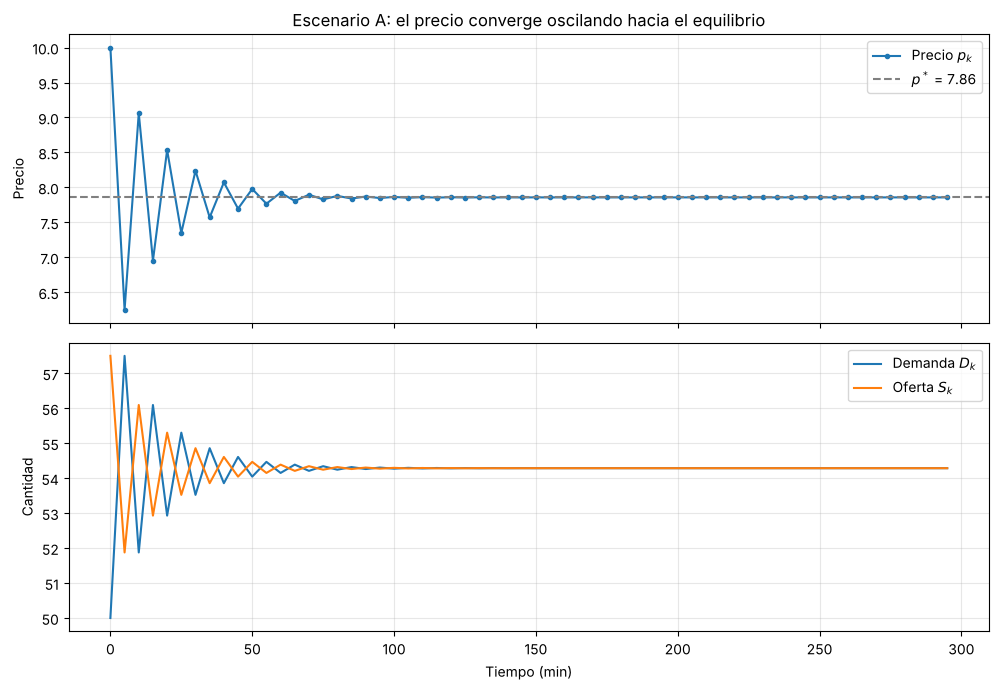

In [2]:
sim = me.simular()
eq = me.equilibrio()

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].plot(sim['t'], sim['p'], 'o-', ms=3, label='Precio $p_k$')
ax[0].axhline(eq['p_eq'], color='gray', ls='--', label=f"$p^*$ = {eq['p_eq']:.2f}")
ax[0].set_ylabel('Precio'); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(sim['t'], sim['D'], label='Demanda $D_k$')
ax[1].plot(sim['t'], sim['S'], label='Oferta $S_k$')
ax[1].set_xlabel('Tiempo (min)'); ax[1].set_ylabel('Cantidad')
ax[1].legend(); ax[1].grid(alpha=0.3)
ax[0].set_title('Escenario A: el precio converge oscilando hacia el equilibrio')
plt.tight_layout(); plt.show()

## 3. Precio de equilibrio teórico

Igualando $D = S$ (sin ruido):

$$p^* = \frac{D_0 - S_0 + \beta\, p_{ref} + \gamma\, p_{costo}}{\beta + \gamma}
= \frac{50 - 50 + 2(10) + 1.5(5)}{3.5} = \frac{27.5}{3.5} \approx 7.857$$

Como $p_0 = 10 \ne p^*$, en el Escenario A el precio **no** se queda quieto: baja hacia 7.86.

In [3]:
pd.DataFrame({
    'Escenario': ['A (equilibrio)', 'B (hora punta, D0=100)', 'C (lluvia, S0=30)'],
    **{k: [me.equilibrio(D0=d, S0=s)[k] for d, s in [(50,50),(100,50),(50,30)]]
       for k in ['p_eq', 'D_eq', 'S_eq']}
}).round(3)

,Escenario,p_eq,D_eq,S_eq
0,A (equilibrio),7.857,54.286,54.286
1,"B (hora punta, D0=100)",22.143,75.714,75.714
2,"C (lluvia, S0=30)",13.571,42.857,42.857


## 4. Condición de estabilidad

Definiendo el error $e_k = p_k - p^*$ y restando $p^*$ a ambos lados de la ecuación de Euler:

$$e_{k+1} = \underbrace{\big(1 - \Delta t\,\alpha(\beta+\gamma)\big)}_{r}\, e_k$$

- Estable si $|r| < 1 \iff 0 < \Delta t\,\alpha(\beta+\gamma) < 2$.
- Si $r < 0$ (producto $> 1$) el error cambia de signo en cada paso: **oscila**.
- Con los valores nominales: $5 \cdot 0.1 \cdot 3.5 = 1.75 \Rightarrow r = -0.75$: estable pero oscilante; el error se reduce 25 % por intervalo.
- Límite: $\alpha_{max} = 2 / (\Delta t(\beta+\gamma)) \approx 0.114$. **El $\alpha$ nominal (0.1) está a solo 12 % del límite de inestabilidad.**

In [4]:
pd.DataFrame([me.estabilidad()]).round(4)

,producto,r,estable,oscila,alpha_max,pasos_para_reducir_error_a_1pct
0,1.75,-0.75,True,True,0.1143,16.0078


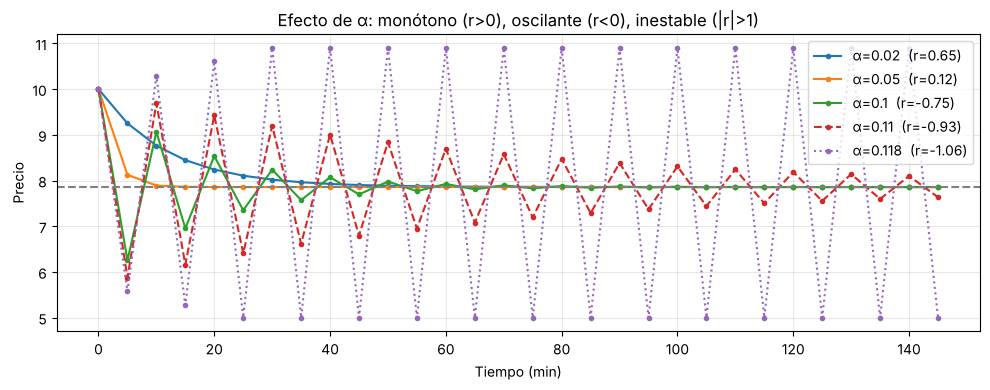

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
for a, estilo in [(0.02, '-'), (0.05, '-'), (0.1, '-'), (0.11, '--'), (0.118, ':')]:
    s = me.simular({'alpha': a, 'T': 150})
    r = me.estabilidad({'alpha': a})['r']
    ax.plot(s['t'], s['p'], estilo, marker='o', ms=3, label=f'α={a}  (r={r:.2f})')
ax.axhline(eq['p_eq'], color='gray', ls='--')
ax.set_xlabel('Tiempo (min)'); ax.set_ylabel('Precio')
ax.set_title('Efecto de α: monótono (r>0), oscilante (r<0), inestable (|r|>1)')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

Mapa de estabilidad en el plano $(\alpha,\ \beta+\gamma)$ con $\Delta t = 5$. La frontera es la hipérbola $\alpha(\beta+\gamma) = 0.4$; la zona entre $0.2$ y $0.4$ es estable pero oscilante.

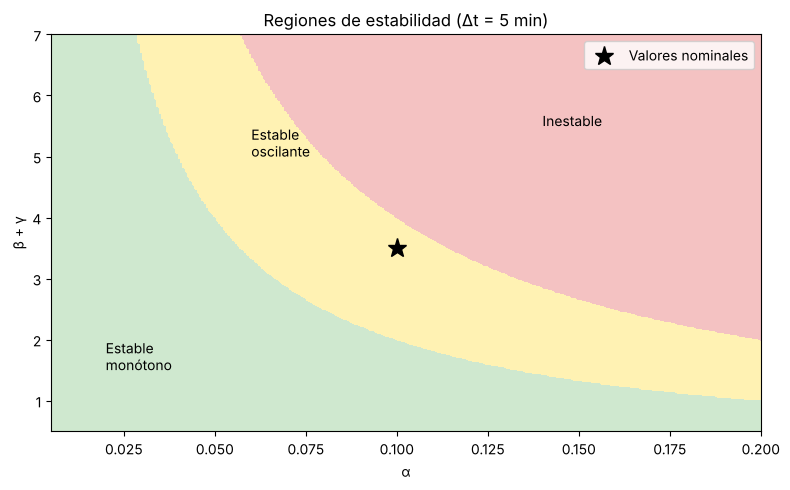

In [6]:
A = np.linspace(0.005, 0.2, 300)
BG = np.linspace(0.5, 7, 300)
AA, GG = np.meshgrid(A, BG)
R = 1 - par['dt'] * AA * GG
zona = np.where(np.abs(R) >= 1, 2, np.where(R < 0, 1, 0))
fig, ax = plt.subplots(figsize=(8, 5))
ax.contourf(AA, GG, zona, levels=[-0.5, 0.5, 1.5, 2.5],
            colors=['#cfe8cf', '#fff2b3', '#f4c2c2'])
ax.plot(par['alpha'], par['beta'] + par['gamma'], 'k*', ms=14, label='Valores nominales')
ax.text(0.02, 1.5, 'Estable\nmonótono'); ax.text(0.06, 5, 'Estable\noscilante')
ax.text(0.14, 5.5, 'Inestable')
ax.set_xlabel('α'); ax.set_ylabel('β + γ'); ax.legend(loc='upper right')
ax.set_title('Regiones de estabilidad (Δt = 5 min)')
plt.tight_layout(); plt.show()

## 5. Métricas por escenario

- **Tiempo hasta equilibrio:** primer instante a partir del cual el precio queda dentro de ±1 % de $p^*$.
- **Intervalos con escasez:** intervalos con $D_k - S_k \ge 1$ (falta al menos un vehículo).
- **Servicios realizados:** $\min(D_k, S_k)$ en cada intervalo.

In [7]:
filas = {}
for nombre, d, s in [('A', 50, 50), ('B', 100, 50), ('C', 50, 30)]:
    m = me.metricas(me.simular(D0=d, S0=s), me.equilibrio(D0=d, S0=s)['p_eq'])
    filas[nombre] = m
pd.DataFrame(filas).T.round(2)

,precio_equilibrio,precio_medio,precio_max,precio_min,tiempo_hasta_equilibrio_min,intervalos_con_escasez,servicios_totales
A,7.86,7.88,10.00,6.25,60.0,4.0,3241.84
B,22.14,22.03,31.25,10.00,70.0,7.0,4459.59
C,13.57,13.54,16.25,10.00,60.0,5.0,2546.94


`simular()` también acepta $D_0$ y $S_0$ variables en el tiempo (arreglo o función de $k$). Ejemplo: hora punta solo entre los minutos 60 y 180 (la Persona 4 lo usa para los escenarios).

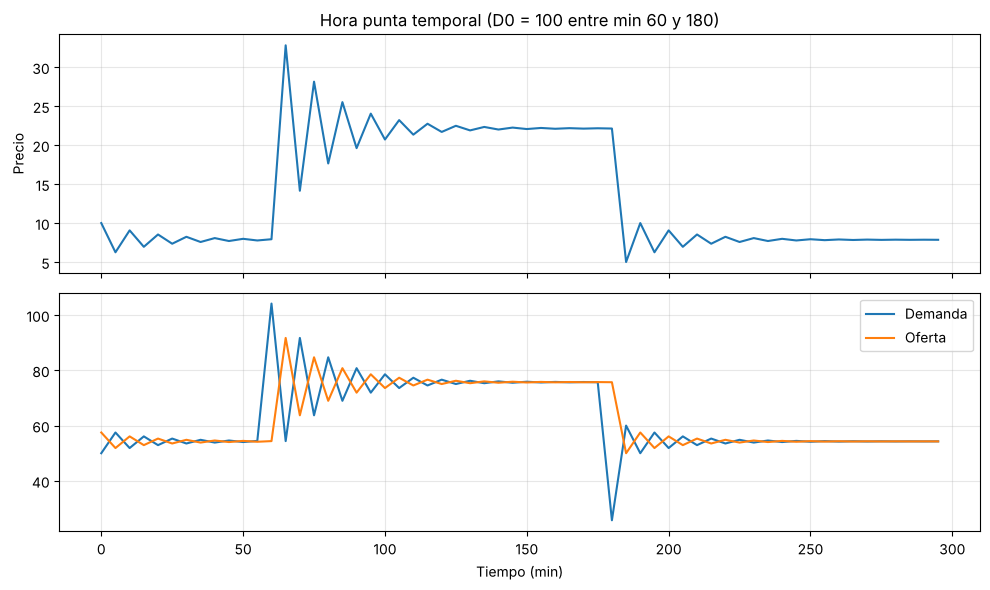

In [8]:
N = int(par['T'] / par['dt'])
D0_t = lambda k: 100.0 if 60 <= k * par['dt'] < 180 else 50.0
s = me.simular(D0=D0_t)
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(s['t'], s['p']); ax[0].set_ylabel('Precio'); ax[0].grid(alpha=0.3)
ax[0].set_title('Hora punta temporal (D0 = 100 entre min 60 y 180)')
ax[1].plot(s['t'], s['D'], label='Demanda'); ax[1].plot(s['t'], s['S'], label='Oferta')
ax[1].set_xlabel('Tiempo (min)'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Choque aleatorio de demanda $\varepsilon_k$

Con `ruido=σ` se agrega $\varepsilon_k \sim \mathcal{N}(0, \sigma^2)$. La `semilla` hace los resultados reproducibles (la Persona 3 debe usar la misma para comparar).

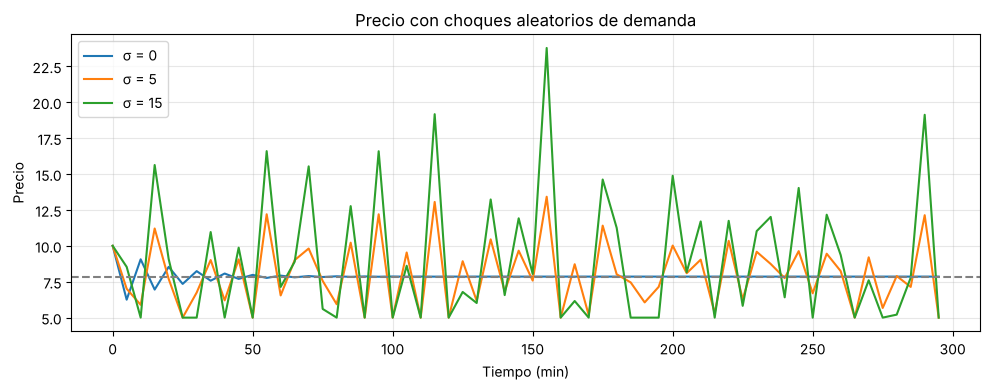

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for sigma in [0, 5, 15]:
    s = me.simular(ruido=sigma, semilla=42)
    ax.plot(s['t'], s['p'], label=f'σ = {sigma}')
ax.axhline(eq['p_eq'], color='gray', ls='--')
ax.set_xlabel('Tiempo (min)'); ax.set_ylabel('Precio'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title('Precio con choques aleatorios de demanda')
plt.tight_layout(); plt.show()

## 7. Matriz $F$ (entrega a la Persona 3)

Con estado $x_k = (p_k, D_k)^\top$ y sin restricciones activas:

$$x_{k+1} = F x_k + B u_k + w_k,\qquad
F = \begin{pmatrix} 1 - \Delta t\alpha\gamma & \Delta t\alpha \\ -\beta(1-\Delta t\alpha\gamma) & -\beta\Delta t\alpha \end{pmatrix}
= \begin{pmatrix} 0.25 & 0.5 \\ -0.5 & -1.0 \end{pmatrix}$$

$$B u_k = \begin{pmatrix} c_1 \\ D_0 + \beta p_{ref} - \beta c_1 \end{pmatrix},\quad c_1 = \Delta t\alpha(\gamma p_{costo} - S_0),\qquad w_k = (0,\ \varepsilon_{k+1})^\top$$

Observaciones para la Persona 3:
- Los autovalores de $F$ son $0$ y $-0.75$: el $-0.75$ es el mismo $r$ de la estabilidad. El $0$ aparece porque $D$ no tiene memoria propia, depende solo del precio.
- El ruido de proceso solo entra en la demanda: $Q = \mathrm{diag}(0, \sigma^2)$. Conviene dar a $Q_{11}$ un valor pequeño positivo para que el filtro no se vuelva demasiado confiado en el precio.
- La forma lineal deja de valer si se activa el piso $p \ge p_{costo}$ o $D, S \ge 0$.

In [10]:
F = me.matriz_F(); Bu = me.termino_entrada()
print('F =\n', F); print('B·u =', Bu)
print('Autovalores de F:', np.linalg.eigvals(F).real)

# Verificación: F x + B u reproduce exactamente simular() sin restricciones
s = me.simular(restricciones=False)
x = np.array([s['p'][0], s['D'][0]]); err = 0
for k in range(len(s['p']) - 1):
    x = F @ x + Bu
    err = max(err, abs(x[0] - s['p'][k+1]), abs(x[1] - s['D'][k+1]))
print('Error máximo entre F·x + B·u y simular():', err)

F =
 [[ 0.25  0.5 ]
 [-0.5  -1.  ]]
B·u = [-21.25 112.5 ]
Autovalores de F: [ 0.   -0.75]
Error máximo entre F·x + B·u y simular(): 0


## 8. Análisis de sensibilidad (pregunta 1)

Se barre cada parámetro dejando los demás en su valor nominal.

In [11]:
barridos = {
    'alpha': np.linspace(0.02, 0.12, 11),
    'beta':  np.linspace(0.5, 4.0, 11),
    'gamma': np.linspace(0.5, 3.0, 11),
}
tablas = {k: pd.DataFrame(me.sensibilidad(k, v)) for k, v in barridos.items()}
tablas['alpha'].round(3)

,alpha,dt*a*(b+g),r,estable,p_eq,precio_max,t_equilibrio_min
0,0.02,0.350,0.650,True,7.857,10.0,40.0
1,0.03,0.525,0.475,True,7.857,10.0,25.0
2,0.04,0.700,0.300,True,7.857,10.0,15.0
3,0.05,0.875,0.125,True,7.857,10.0,10.0
4,0.06,1.050,-0.050,True,7.857,10.0,10.0
5,0.07,1.225,-0.225,True,7.857,10.0,15.0
6,0.08,1.400,-0.400,True,7.857,10.0,20.0
7,0.09,1.575,-0.575,True,7.857,10.0,30.0
8,0.10,1.750,-0.750,True,7.857,10.0,60.0
9,0.11,1.925,-0.925,True,7.857,10.0,215.0


In [12]:
tablas['beta'].round(3)

,beta,dt*a*(b+g),r,estable,p_eq,precio_max,t_equilibrio_min
0,0.50,1.000,0.000,True,6.250,10.000,5.0
1,0.85,1.175,-0.175,True,6.809,10.000,15.0
2,1.20,1.350,-0.350,True,7.222,10.000,20.0
3,1.55,1.525,-0.525,True,7.541,10.000,30.0
4,1.90,1.700,-0.700,True,7.794,10.000,50.0
5,2.25,1.875,-0.875,True,8.000,10.000,125.0
6,2.60,2.050,-1.050,False,8.171,11.500,NaN
7,2.95,2.225,-1.225,False,8.315,12.375,NaN
8,3.30,2.400,-1.400,False,8.438,13.250,NaN
9,3.65,2.575,-1.575,False,8.544,14.125,NaN


In [13]:
tablas['gamma'].round(3)

,gamma,dt*a*(b+g),r,estable,p_eq,precio_max,t_equilibrio_min
0,0.50,1.250,-0.250,True,9.000,10.0,10.0
1,0.75,1.375,-0.375,True,8.636,10.0,15.0
2,1.00,1.500,-0.500,True,8.333,10.0,25.0
3,1.25,1.625,-0.625,True,8.077,10.0,35.0
4,1.50,1.750,-0.750,True,7.857,10.0,60.0
5,1.75,1.875,-0.875,True,7.667,10.0,130.0
6,2.00,2.000,-1.000,False,7.500,10.0,NaN
7,2.25,2.125,-1.125,False,7.353,10.0,NaN
8,2.50,2.250,-1.250,False,7.222,10.0,NaN
9,2.75,2.375,-1.375,False,7.105,10.0,NaN


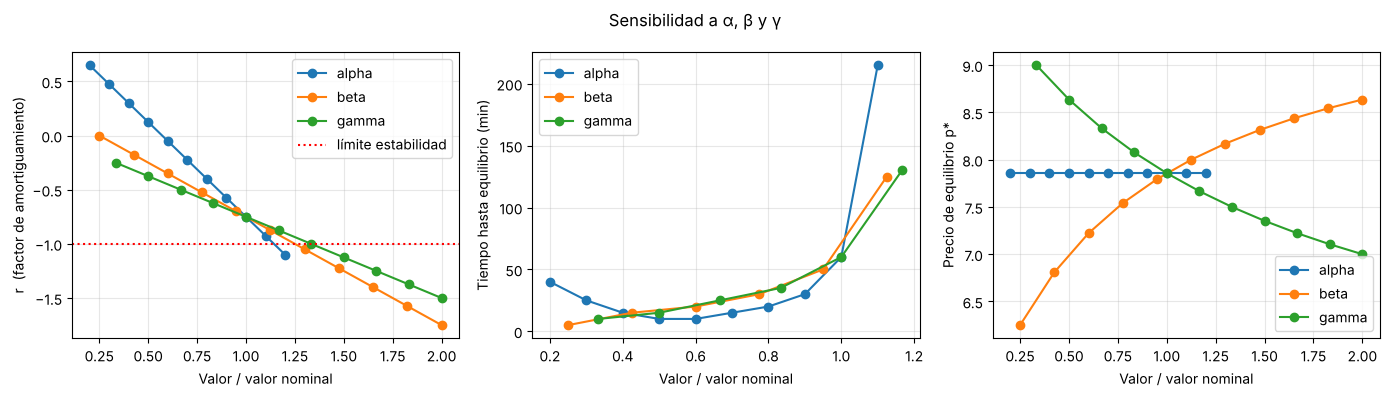

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for i, (k, df) in enumerate(tablas.items()):
    ax[0].plot(df[k] / par[k], df['r'], 'o-', label=k)
    ax[1].plot(df[k] / par[k], df['t_equilibrio_min'], 'o-', label=k)
    ax[2].plot(df[k] / par[k], df['p_eq'], 'o-', label=k)
ax[0].axhline(-1, color='r', ls=':', label='límite estabilidad')
ax[0].set_ylabel('r  (factor de amortiguamiento)')
ax[1].set_ylabel('Tiempo hasta equilibrio (min)')
ax[2].set_ylabel('Precio de equilibrio p*')
for a in ax:
    a.set_xlabel('Valor / valor nominal'); a.grid(alpha=0.3); a.legend()
fig.suptitle('Sensibilidad a α, β y γ')
plt.tight_layout(); plt.show()

Elasticidad local del precio de equilibrio (cambio % de $p^*$ por cambio de 1 % en cada parámetro), calculada por diferencias finitas:

In [15]:
def elasticidad(nombre, h=1e-4):
    p0 = me.equilibrio()['p_eq']
    p1 = me.equilibrio({nombre: par[nombre] * (1 + h)})['p_eq']
    return (p1 - p0) / p0 / h
pd.Series({k: elasticidad(k) for k in ['alpha', 'beta', 'gamma', 'p_ref', 'p_costo']},
          name='Elasticidad de p*').round(3)

alpha      0.000
beta       0.156
gamma     -0.156
p_ref      0.727
p_costo    0.273
Name: Elasticidad de p*, dtype: float64

### Conclusiones del análisis

1. **α solo afecta la dinámica, no el destino.** No aparece en $p^*$ (elasticidad 0), pero controla la rapidez y la oscilación. Es el parámetro más crítico para la estabilidad: con $\alpha > 0.114$ el precio diverge. Con $\alpha \approx 0.057$ ($r \approx 0$) el ajuste es casi instantáneo, sin oscilación.
2. **β y γ afectan la dinámica solo a través de su suma** ($r = 1 - \Delta t\alpha(\beta+\gamma)$), pero cada uno mueve el equilibrio en sentido distinto: más β sube $p^*$ (hacia $p_{ref}$) y más γ lo baja (hacia $p_{costo}$). Si suben mucho, también empujan al sistema hacia la inestabilidad.
3. **Las oscilaciones son de periodo 2** (sube–baja–sube) siempre que $r<0$; su amplitud decae como $|r|^k$. No hay otras frecuencias porque el sistema de precio es de primer orden.
4. **Qué conviene estimar con más precisión:** α, porque el valor nominal está cerca del límite de inestabilidad y un error de ~15 % cambia el comportamiento cualitativo. Para el precio de equilibrio importan más β y γ.
5. **Qué pasa al cruzar el límite:** en las tablas, los casos inestables no explotan a infinito porque el piso $p \ge p_{costo}$ corta la caída; el precio queda rebotando entre el costo y un máximo que crece con el parámetro (ciclo sostenido). En la realidad eso sería un precio que salta cada 5 minutos sin asentarse.
6. **Recomendación de diseño:** en el sistema real la plataforma elige α (qué tan agresivo ajusta el precio). Un $\alpha$ entre 0.04 y 0.06 da convergencia rápida sin oscilaciones que confundan a pasajeros y conductores.